Epoch   GD loss    SGD loss
    1     1.6363     0.1543
   10     0.4704     0.0693
   20     0.1492     0.0685
   30     0.0730     0.0677
   40     0.0613     0.0670
   50     0.0593     0.0672
   60     0.0586     0.0671
Gradient Descent (batch = 200)   final loss = 0.0586, std of epoch-to-epoch change (last 30) = 0.00050
SGD (batch = 1)                  final loss = 0.0671, std of epoch-to-epoch change (last 30) = 0.00032

Updates (out of 199 SGD updates) where the loss went UP : 100
Updates (out of 59 GD updates) where the loss went UP  : 0
Largest single-update increase in loss for SGD : 0.0671


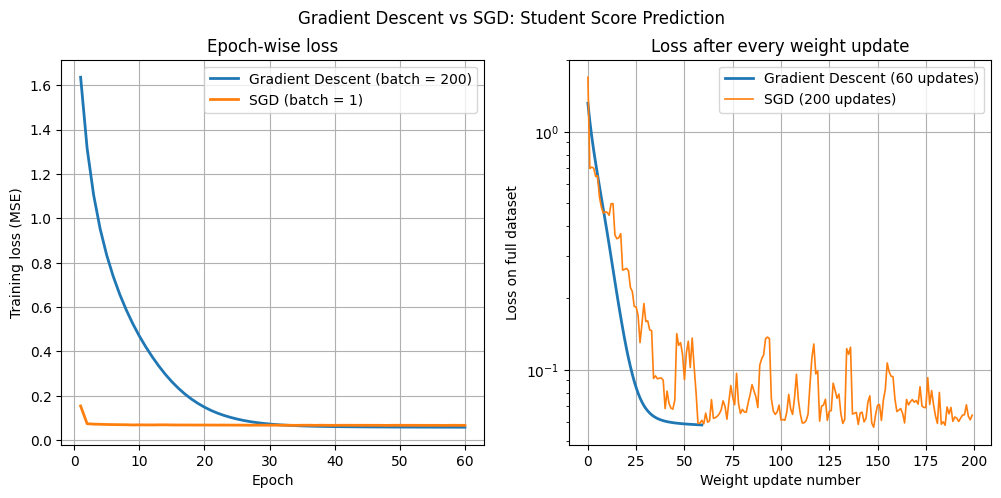

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

np.random.seed(1)
tf.keras.utils.set_random_seed(1)

# Step 1: Student data (attendance %, internal marks /50) -> exam score /100
n = 200
attendance = np.random.uniform(50, 100, n)
internal = np.random.uniform(10, 50, n)
score = 0.4 * attendance + 1.0 * internal + np.random.normal(0, 3, n)
X = np.column_stack([attendance, internal])
y = score.reshape(-1, 1)

# Step 2: Standardise inputs and target
X = (X - X.mean(axis=0)) / X.std(axis=0)
y = (y - y.mean()) / y.std()

# Step 3: Build the same network for each optimizer
def build_model():
    tf.keras.utils.set_random_seed(1)            # identical initial weights
    return keras.Sequential([
        keras.layers.Input(shape=(2,)),
        keras.layers.Dense(8, activation="relu"),
        keras.layers.Dense(1)])

epochs, lr = 60, 0.05
losses = {}

# Callback that records the loss on the whole dataset after every weight update
class UpdateLoss(keras.callbacks.Callback):
    def __init__(self, max_updates):
        super().__init__()
        self.values = []
        self.max_updates = max_updates
    def on_train_batch_end(self, batch, logs=None):
        if len(self.values) < self.max_updates:
            pred = self.model(X, training=False).numpy()
            self.values.append(float(np.mean((pred - y) ** 2)))

# Gradient Descent: full batch (one update per epoch)
model_gd = build_model()
model_gd.compile(optimizer=keras.optimizers.SGD(learning_rate=lr), loss="mse")
cb_gd = UpdateLoss(60)
h = model_gd.fit(X, y, epochs=epochs, batch_size=len(X), verbose=0, callbacks=[cb_gd])
losses["Gradient Descent (batch = 200)"] = np.array(h.history["loss"])

# SGD: one sample per update (200 updates per epoch)
model_sgd = build_model()
model_sgd.compile(optimizer=keras.optimizers.SGD(learning_rate=lr), loss="mse")
cb_sgd = UpdateLoss(200)
h = model_sgd.fit(X, y, epochs=epochs, batch_size=1, shuffle=True, verbose=0, callbacks=[cb_sgd])
losses["SGD (batch = 1)"] = np.array(h.history["loss"])

# Step 4: Analyse the stored loss values
print("Epoch   GD loss    SGD loss")
for e in [1, 10, 20, 30, 40, 50, 60]:
    print(f"{e:5d}  {losses['Gradient Descent (batch = 200)'][e-1]:9.4f}  "
          f"{losses['SGD (batch = 1)'][e-1]:9.4f}")
for k, v in losses.items():
    print(f"{k:32s} final loss = {v[-1]:.4f}, "
          f"std of epoch-to-epoch change (last 30) = {np.std(np.diff(v[-30:])):.5f}")

# Loss after each individual weight update (first 200 updates) for the noise analysis
upd_gd = np.array(cb_gd.values)
upd_sgd = np.array(cb_sgd.values)
rises_sgd = int(np.sum(np.diff(upd_sgd) > 0))
rises_gd = int(np.sum(np.diff(upd_gd) > 0))
print("\nUpdates (out of", len(upd_sgd) - 1, "SGD updates) where the loss went UP :", rises_sgd)
print("Updates (out of", len(upd_gd) - 1, "GD updates) where the loss went UP  :", rises_gd)
print("Largest single-update increase in loss for SGD :",
      round(float(np.max(np.diff(upd_sgd))), 4))

# Step 5: Plot the loss curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for k, v in losses.items():
    axes[0].plot(range(1, epochs + 1), v, label=k, linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training loss (MSE)")
axes[0].set_title("Epoch-wise loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(upd_gd, label="Gradient Descent (60 updates)", linewidth=2)
axes[1].plot(upd_sgd, label="SGD (200 updates)", linewidth=1.2)
axes[1].set_yscale("log")
axes[1].set_xlabel("Weight update number")
axes[1].set_ylabel("Loss on full dataset")
axes[1].set_title("Loss after every weight update")
axes[1].legend()
axes[1].grid(True)
plt.suptitle("Gradient Descent vs SGD: Student Score Prediction")
plt.show()